# Week 7: Capstone: Model Risk Across GBM, Jump, and Regime-Switching Models

**Project:** *Valuing Variable Annuity Guarantees Under Market Crashes and Regime Shifts*  
**Mentor:** Hao Quan  
**Notebook type:** all-in-one lesson, lab, exercises, and worked solutions

> **Driving question:** How much gross GMAB risk can a smooth-market model miss under explicit crash and stress assumptions?

## Learning goals

- Run three models under one contract and one reporting framework.
- Separate Monte Carlo sampling error from model-specification differences.
- Compare value, trigger probability, severity, and lower-tail outcomes.
- Explain why cross-model rankings are calibration-specific.
- Produce an evidence-based conclusion for a non-specialist actuarial audience.

## How to use this notebook

1. Complete the assigned reading before the weekly meeting.
2. Read the explanation cells and predict each result before running the code.
3. Run the notebook from top to bottom. Every random experiment uses a fixed seed.
4. Attempt the exercises before opening the worked-solution section.
5. Write a 150–250 word interpretation of the main result in your own words.

This notebook is educational. It simplifies real contracts and is not an insurance
quotation, investment recommendation, or complete actuarial valuation.

## Assigned reading

- [SOA: Hedging Variable Annuities—A Dealer's Perspective](https://www.soa.org/library/newsletters/the-actuary-magazine/2005/april/hed2005april/) — read the article and identify the four major guarantee types and embedded-option exposure
- [Penn Freedom prospectus](https://www.sec.gov/Archives/edgar/data/702184/000119312522115288/d269677d485bpos.htm) — revisit the rider clauses and list every commercial feature excluded from this capstone
- [Merton and Hamilton readings](https://dspace.mit.edu/entities/publication/e63635d9-d2bf-40ce-a79b-67786dd9f105) — revisit each model's motivation and limits

## Presentation structure
- Readings
- VA
- problem formulation
- models
- model assumptions
- monte-carlo simulation
- experiment design
- results
- conclusion
- future research


In [2]:
import math
from dataclasses import dataclass

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
np.set_printoptions(precision=4, suppress=True)

SEED = 20260730
rng = np.random.default_rng(SEED)
print(f"Reproducible random seed: {SEED}")


Reproducible random seed: 20260730


## 1. Research question and scope

We compare the present value of the same stylized gross maturity shortfall,

$$V_0^{(m)}=e^{-rT}E^{Q_m}[(G-A_T^{(m)})^+],$$

under three model specifications $m$:

1. smooth GBM;
2. Merton-style negative jumps;
3. two-state Markov regime switching.

The expectations use model-specific, illustrative pricing measures $Q_m$.
The resulting tail statistics are **risk-neutral pricing diagnostics**, not
real-world economic-capital VaR.

This notebook is independent: it does not import functions or outputs from
Weeks 1–6.


In [4]:
@dataclass(frozen=True)
class Contract:
    A0: float = 100_000.0
    G: float = 100_000.0
    T: float = 10.0
    r: float = 0.03
    charge: float = 0.02


@dataclass(frozen=True)
class JumpParameters:
    sigma: float = 0.16
    intensity: float = 0.15
    mean_log_jump: float = -0.25
    sd_log_jump: float = 0.12


@dataclass(frozen=True)
class RegimeParameters:
    sigmas: tuple = (0.16, 0.45)
    transition: tuple = ((0.985, 0.015), (0.150, 0.850))
    steps_per_year: int = 12


contract = Contract()
gbm_sigma = 0.16
jump_parameters = JumpParameters()
regime_parameters = RegimeParameters()
N_PATHS = 100_000

print(contract)
print(jump_parameters)
print(regime_parameters)
print(f"Main Monte Carlo sample size per model: {N_PATHS:,}")


Contract(A0=100000.0, G=100000.0, T=10.0, r=0.03, charge=0.02)
JumpParameters(sigma=0.16, intensity=0.15, mean_log_jump=-0.25, sd_log_jump=0.12)
RegimeParameters(sigmas=(0.16, 0.45), transition=((0.985, 0.015), (0.15, 0.85)), steps_per_year=12)
Main Monte Carlo sample size per model: 100,000


## 2. Unified simulation functions


In [8]:
def simulate_gbm_terminal(contract, sigma, n_paths, seed=SEED, z=None):
    if z is None:
        z = np.random.default_rng(seed).standard_normal(n_paths)
    z = np.asarray(z)
    return contract.A0 * np.exp(
        (contract.r-contract.charge-0.5*sigma**2)*contract.T
        + sigma*np.sqrt(contract.T)*z
    )


def jump_compensator(mean_log_jump, sd_log_jump):
    return np.exp(mean_log_jump + 0.5*sd_log_jump**2)-1


def simulate_jump_terminal(contract, p, n_paths, seed=SEED, z_diffusion=None):
    generator = np.random.default_rng(seed)
    if z_diffusion is None:
        z_diffusion = generator.standard_normal(n_paths)
    else:
        z_diffusion = np.asarray(z_diffusion)
    counts = generator.poisson(p.intensity*contract.T, n_paths)
    z_jump = generator.standard_normal(n_paths)
    aggregate_log_jump = (
        counts*p.mean_log_jump + np.sqrt(counts)*p.sd_log_jump*z_jump
    )
    kappa = jump_compensator(p.mean_log_jump, p.sd_log_jump)
    return contract.A0*np.exp(
        (contract.r-contract.charge-p.intensity*kappa-0.5*p.sigma**2)*contract.T
        + p.sigma*np.sqrt(contract.T)*z_diffusion
        + aggregate_log_jump
    )


def validate_transition(matrix):
    matrix = np.asarray(matrix, dtype=float)
    if matrix.shape != (2, 2) or np.any(matrix < 0) or not np.allclose(matrix.sum(axis=1), 1):
        raise ValueError("use a valid 2x2 transition matrix")
    return matrix


def simulate_regime_terminal(contract, p, n_paths, seed=SEED):
    matrix = validate_transition(p.transition)
    sigmas = np.asarray(p.sigmas, dtype=float)
    n_steps = int(contract.T*p.steps_per_year)
    dt = contract.T/n_steps
    generator = np.random.default_rng(seed)
    states = np.zeros(n_paths, dtype=np.int8)
    log_accounts = np.full(n_paths, np.log(contract.A0))
    for _ in range(n_steps):
        z = generator.standard_normal(n_paths)
        step_sigma = sigmas[states]
        log_accounts += (
            (contract.r-contract.charge-0.5*step_sigma**2)*dt
            + step_sigma*np.sqrt(dt)*z
        )
        u = generator.random(n_paths)
        p_next_crisis = np.where(states == 0, matrix[0,1], matrix[1,1])
        states = (u < p_next_crisis).astype(np.int8)
    return np.exp(log_accounts)


## 3. Common reporting function

For each model we report:

- gross GMAB present value and Monte Carlo standard error;
- 95% confidence interval for the mean;
- probability of a maturity claim;
- mean undiscounted shortfall conditional on a claim;
- lower terminal-account quantiles;
- 95% and 99% quantiles and expected shortfall of the **discounted pricing loss**.


In [11]:
def tail_mean(values, quantile_level):
    threshold = np.quantile(values, quantile_level)
    return threshold, values[values >= threshold].mean()


def summarize_model(name, terminal_accounts, contract):
    terminal_accounts = np.asarray(terminal_accounts)
    payoff = np.maximum(contract.G-terminal_accounts, 0)
    pv_loss = np.exp(-contract.r*contract.T)*payoff
    price = pv_loss.mean()
    se = pv_loss.std(ddof=1)/np.sqrt(len(pv_loss))
    q95, es95 = tail_mean(pv_loss, 0.95)
    q99, es99 = tail_mean(pv_loss, 0.99)
    triggered = payoff > 0
    return {
        "model": name,
        "value": price,
        "MC_SE": se,
        "CI_low": price-1.96*se,
        "CI_high": price+1.96*se,
        "trigger_probability": triggered.mean(),
        "conditional_shortfall": payoff[triggered].mean() if triggered.any() else 0,
        "account_p01": np.quantile(terminal_accounts, 0.01),
        "account_p05": np.quantile(terminal_accounts, 0.05),
        "account_median": np.median(terminal_accounts),
        "PV_loss_q95": q95,
        "PV_loss_ES95": es95,
        "PV_loss_q99": q99,
        "PV_loss_ES99": es99,
    }, pv_loss


## 4. Main cross-model experiment
$$E^{Q_m}[(G-A_T^{(m)})^+]$$
$$frac{1}/{N} \sum_{i=1}^{N}[(G_i-A_T_i^{(m)})^+]$$

In [14]:
seed_sequence = np.random.SeedSequence(SEED)
child_seeds = seed_sequence.spawn(3)
seed_gbm = int(child_seeds[0].generate_state(1)[0])
seed_jump = int(child_seeds[1].generate_state(1)[0])
seed_regime = int(child_seeds[2].generate_state(1)[0])

A_gbm = simulate_gbm_terminal(contract, gbm_sigma, N_PATHS, seed=seed_gbm)
A_jump = simulate_jump_terminal(contract, jump_parameters, N_PATHS, seed=seed_jump)
A_regime = simulate_regime_terminal(contract, regime_parameters, N_PATHS, seed=seed_regime)

summaries = []
losses = {}
for name, accounts in [
    ("GBM", A_gbm),
    ("Jump diffusion", A_jump),
    ("Regime switching", A_regime),
]:
    row, pv_loss = summarize_model(name, accounts, contract)
    summaries.append(row)
    losses[name] = pv_loss

results = pd.DataFrame(summaries)
gbm_value = results.loc[results["model"]=="GBM", "value"].iloc[0]
results["difference_from_GBM"] = results["value"]-gbm_value
results["percent_uplift_from_GBM"] = results["value"]/gbm_value-1

main_columns = [
    "model", "value", "MC_SE", "CI_low", "CI_high",
    "trigger_probability", "conditional_shortfall",
    "difference_from_GBM", "percent_uplift_from_GBM",
]
print(results[main_columns].to_string(index=False, formatters={
    "value": "${:,.2f}".format,
    "MC_SE": "${:,.2f}".format,
    "CI_low": "${:,.2f}".format,
    "CI_high": "${:,.2f}".format,
    "trigger_probability": "{:.2%}".format,
    "conditional_shortfall": "${:,.2f}".format,
    "difference_from_GBM": "${:,.2f}".format,
    "percent_uplift_from_GBM": "{:.1%}".format,
}))

upper_bound = contract.G*np.exp(-contract.r*contract.T)
assert results["value"].between(0, upper_bound).all()
assert np.isfinite(results.select_dtypes(include=[np.number])).all().all()


           model      value  MC_SE     CI_low    CI_high trigger_probability conditional_shortfall difference_from_GBM percent_uplift_from_GBM
             GBM $11,988.35 $48.20 $11,893.88 $12,082.82              52.36%            $30,907.57               $0.00                    0.0%
  Jump diffusion $14,740.80 $56.51 $14,630.04 $14,851.56              54.42%            $36,561.75           $2,752.45                   23.0%
Regime switching $15,662.18 $58.27 $15,547.96 $15,776.40              56.15%            $37,652.24           $3,673.83                   30.6%


## 5. Visual comparison with uncertainty


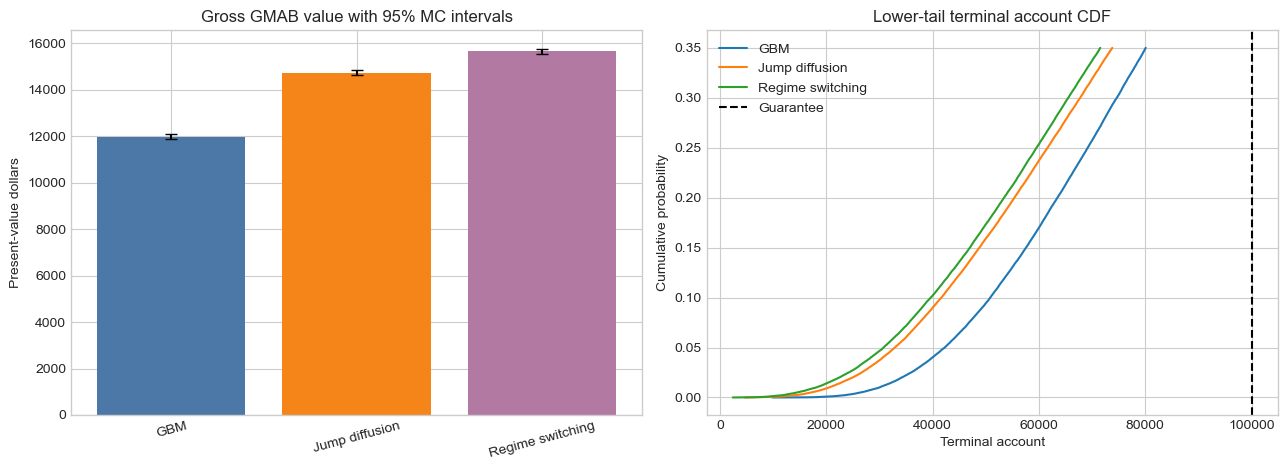

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
x = np.arange(len(results))
axes[0].bar(x, results["value"], color=["#4C78A8", "#F58518", "#B279A2"])
axes[0].errorbar(
    x, results["value"], yerr=1.96*results["MC_SE"],
    fmt="none", ecolor="black", capsize=4
)
axes[0].set_xticks(x, results["model"], rotation=15)
axes[0].set(title="Gross GMAB value with 95% MC intervals", ylabel="Present-value dollars")

for name, accounts in [("GBM", A_gbm), ("Jump diffusion", A_jump), ("Regime switching", A_regime)]:
    sorted_accounts = np.sort(accounts)
    cdf = np.arange(1, len(accounts)+1)/len(accounts)
    mask = cdf <= 0.35
    axes[1].plot(sorted_accounts[mask], cdf[mask], label=name)
axes[1].axvline(contract.G, color="black", linestyle="--", label="Guarantee")
axes[1].set(title="Lower-tail terminal account CDF", xlabel="Terminal account", ylabel="Cumulative probability")
axes[1].legend()
plt.tight_layout()
plt.show()


## 6. Tail diagnostics


           model account_p01 account_p05 account_median PV_loss_q95 PV_loss_ES95 PV_loss_q99 PV_loss_ES99
             GBM  $29,965.15  $42,282.51     $97,003.30  $42,758.17   $48,350.40  $51,883.09   $55,071.39
  Jump diffusion  $20,560.34  $32,930.92     $93,586.90  $49,685.99   $55,257.36  $58,850.34   $61,944.21
Regime switching  $18,131.95  $30,795.81     $90,959.11  $51,267.72   $57,016.30  $60,649.35   $63,794.49


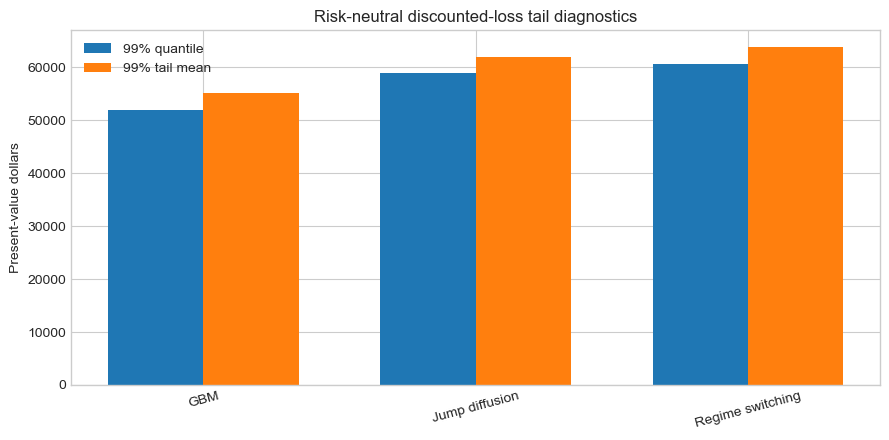

In [20]:
tail_columns = [
    "model", "account_p01", "account_p05", "account_median",
    "PV_loss_q95", "PV_loss_ES95", "PV_loss_q99", "PV_loss_ES99",
]
print(results[tail_columns].to_string(index=False, formatters={
    c: "${:,.2f}".format for c in tail_columns if c != "model"
}))

fig, ax = plt.subplots(figsize=(9, 4.5))
width = 0.35
ax.bar(x-width/2, results["PV_loss_q99"], width, label="99% quantile")
ax.bar(x+width/2, results["PV_loss_ES99"], width, label="99% tail mean")
ax.set_xticks(x, results["model"], rotation=15)
ax.set(title="Risk-neutral discounted-loss tail diagnostics", ylabel="Present-value dollars")
ax.legend()
plt.tight_layout()
plt.show()


## 7. Limiting-case validation

A credible model implementation should recover simpler models:

- jump diffusion with $\lambda=0$ reduces to GBM;
- regime switching with equal volatilities reduces to GBM, regardless of states.


In [23]:
test_n = 20_000
test_rng = np.random.default_rng(SEED + 100)
z = test_rng.standard_normal(test_n)
gbm_test = simulate_gbm_terminal(contract, 0.16, test_n, z=z)
no_jump_p = JumpParameters(intensity=0.0)
no_jump_test = simulate_jump_terminal(
    contract, no_jump_p, test_n, seed=SEED + 101, z_diffusion=z
)
print(f"Max jump-to-GBM difference at lambda=0: {np.max(np.abs(no_jump_test-gbm_test)):.3e}")
assert np.allclose(no_jump_test, gbm_test)

# Equal-volatility regime test using explicitly shared monthly normal shocks.
steps = int(contract.T*12)
limit_rng = np.random.default_rng(SEED + 102)
z_monthly = limit_rng.standard_normal((4_000, steps))
u_monthly = limit_rng.random((4_000, steps))
matrix = validate_transition(regime_parameters.transition)
states = np.zeros(4_000, dtype=np.int8)
log_regime = np.full(4_000, np.log(contract.A0))
dt = contract.T/steps
for k in range(steps):
    sigma_equal = 0.16
    log_regime += (
        (contract.r-contract.charge-0.5*sigma_equal**2)*dt
        + sigma_equal*np.sqrt(dt)*z_monthly[:, k]
    )
    p_next = np.where(states==0, matrix[0,1], matrix[1,1])
    states = (u_monthly[:, k] < p_next).astype(np.int8)
regime_equal = np.exp(log_regime)
z_aggregated = z_monthly.sum(axis=1)/np.sqrt(steps)
gbm_equal = simulate_gbm_terminal(contract, 0.16, len(regime_equal), z=z_aggregated)
print(f"Max equal-volatility regime-to-GBM difference: {np.max(np.abs(regime_equal-gbm_equal)):.3e}")
assert np.allclose(regime_equal, gbm_equal, rtol=1e-11, atol=1e-7)


Max jump-to-GBM difference at lambda=0: 0.000e+00
Max equal-volatility regime-to-GBM difference: 6.752e-09


## 8. Controlled sensitivities

These are scenario experiments, not calibrated forecasts. Each curve changes
one parameter while holding the contract and other model inputs fixed.


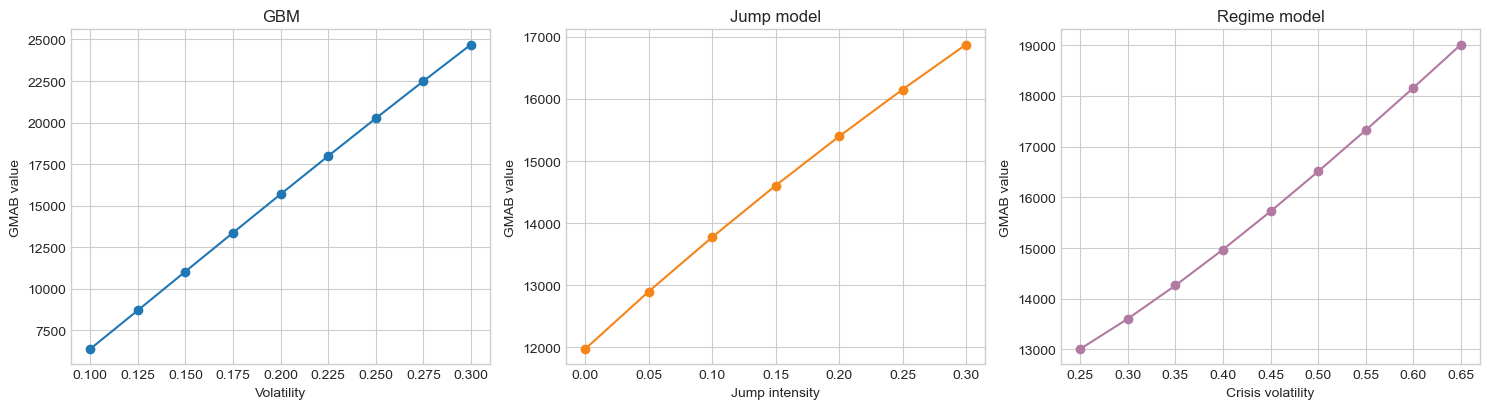

In [26]:
def gbm_put_value(contract, sigma):
    d1 = (
        np.log(contract.A0/contract.G)
        +(contract.r-contract.charge+0.5*sigma**2)*contract.T
    )/(sigma*np.sqrt(contract.T))
    d2 = d1-sigma*np.sqrt(contract.T)
    return (
        contract.G*np.exp(-contract.r*contract.T)*norm.cdf(-d2)
        - contract.A0*np.exp(-contract.charge*contract.T)*norm.cdf(-d1)
    )


def expected_put_log_normal(log_mean, log_variance, strike):
    sd = np.sqrt(log_variance)
    a = (np.log(strike)-log_mean)/sd
    return strike*norm.cdf(a)-np.exp(log_mean+0.5*log_variance)*norm.cdf(a-sd)


def jump_mixture_value(contract, p, tol=1e-12):
    lam_T = p.intensity*contract.T
    probability = np.exp(-lam_T)
    cumulative = 0.0
    value = 0.0
    n = 0
    kappa = jump_compensator(p.mean_log_jump, p.sd_log_jump)
    while True:
        mean = (
            np.log(contract.A0)
            +(contract.r-contract.charge-p.intensity*kappa-0.5*p.sigma**2)*contract.T
            +n*p.mean_log_jump
        )
        variance = p.sigma**2*contract.T+n*p.sd_log_jump**2
        value += probability*expected_put_log_normal(mean, variance, contract.G)
        cumulative += probability
        if 1-cumulative < tol:
            break
        n += 1
        probability *= lam_T/n
    return np.exp(-contract.r*contract.T)*value


gbm_vols = np.linspace(0.10, 0.30, 9)
gbm_curve = [gbm_put_value(contract, s) for s in gbm_vols]

jump_lambdas = np.linspace(0.00, 0.30, 7)
jump_curve = [
    jump_mixture_value(
        contract,
        JumpParameters(
            sigma=jump_parameters.sigma,
            intensity=float(lam),
            mean_log_jump=jump_parameters.mean_log_jump,
            sd_log_jump=jump_parameters.sd_log_jump,
        )
    )
    for lam in jump_lambdas
]

crisis_sigmas = np.linspace(0.25, 0.65, 9)
regime_curve = []
for crisis_sigma in crisis_sigmas:
    p = RegimeParameters(sigmas=(0.16, float(crisis_sigma)))
    accounts = simulate_regime_terminal(contract, p, 30_000, seed=SEED + 200)
    regime_curve.append(np.exp(-contract.r*contract.T)*np.maximum(contract.G-accounts, 0).mean())

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
axes[0].plot(gbm_vols, gbm_curve, marker="o")
axes[0].set(title="GBM", xlabel="Volatility", ylabel="GMAB value")
axes[1].plot(jump_lambdas, jump_curve, marker="o", color="#F58518")
axes[1].set(title="Jump model", xlabel="Jump intensity", ylabel="GMAB value")
axes[2].plot(crisis_sigmas, regime_curve, marker="o", color="#B279A2")
axes[2].set(title="Regime model", xlabel="Crisis volatility", ylabel="GMAB value")
plt.tight_layout()
plt.show()

assert np.all(np.diff(gbm_curve) > 0)
assert np.all(np.diff(jump_curve) >= -1e-8)


## 9. Interpretation framework

When writing the conclusion, separate three layers:

1. **Numerical uncertainty:** How large are the Monte Carlo standard errors?
2. **Model uncertainty:** How far apart are the model-conditioned values?
3. **Parameter uncertainty:** Would a different jump intensity, crisis
   persistence, or volatility ranking reverse the conclusion?

Do not write “the true value is the regime-switching value.” A defensible
statement is: *under the stated illustrative pricing specifications, the
smooth model produces a lower gross GMAB value by X dollars (Y%) than the
specified jump/regime alternatives.*

## 10. Final report assignment

Prepare a 3–4 page technical report and an 8–10 minute presentation containing:

1. Contract and payoff definition
2. Three model equations and pricing assumptions
3. Validation tests
4. Main comparison table with MC uncertainty
5. One controlled sensitivity
6. Product and model limitations
7. A 150–250 word recommendation to an insurer's risk committee

The recommendation should discuss model-risk stress/loading, gap risk,
persistent volatility, product design, investment restrictions, or reinsurance
without claiming that a richer uncalibrated model is automatically correct.


## 11. Capstone exercises

1. Calculate dollar and percentage understatement relative to GBM.
2. Identify whether the cross-model difference is large relative to the two
   Monte Carlo standard errors.
3. Change the guarantee to 110% of premium and repeat the table.
4. List at least eight real-contract features omitted from the analysis.
5. Explain why pricing under $Q$ and capital assessment under $P$ are related
   but different tasks.


## 12. Worked solutions and prompts


In [ ]:
# Exercises 1 and 2
comparison_to_gbm = results[[
    "model", "difference_from_GBM", "percent_uplift_from_GBM", "MC_SE"
]].copy()
comparison_to_gbm["difference_in_combined_SE"] = [
    0.0,
    (results.loc[1, "value"]-results.loc[0, "value"]) /
    np.sqrt(results.loc[1, "MC_SE"]**2+results.loc[0, "MC_SE"]**2),
    (results.loc[2, "value"]-results.loc[0, "value"]) /
    np.sqrt(results.loc[2, "MC_SE"]**2+results.loc[0, "MC_SE"]**2),
]
print(comparison_to_gbm.to_string(index=False))

# Exercise 3
generous_contract = Contract(G=110_000.0)
generous_rows = []
for name, accounts in [
    ("GBM", A_gbm), ("Jump diffusion", A_jump), ("Regime switching", A_regime)
]:
    row, _ = summarize_model(name, accounts, generous_contract)
    generous_rows.append(row)
print("\n110% guarantee:")
print(pd.DataFrame(generous_rows)[["model", "value", "trigger_probability"]].to_string(index=False))

# Exercise 4 answer prompt:
omissions = [
    "mortality", "lapse/surrender", "withdrawals", "additional premiums",
    "reset/step-up rules", "fund switching", "investment restrictions",
    "tax", "stochastic rates", "hedging costs", "capital", "expenses/profit",
]
print("\nMaterial omissions:")
print(", ".join(omissions))
assert len(omissions) >= 8


## 13. Final takeaways

1. Product terms come before stochastic models.
2. Smooth GBM gives a transparent benchmark and an analytic validation target.
3. Jump and regime models capture distinct forms of tail/path risk.
4. Monte Carlo error can be small while model uncertainty remains material.
5. Every result is conditional on the stated contract, pricing measure, and parameters.

### Final submission

- Fully executed capstone notebook
- 3–4 page technical report
- 8–10 minute presentation
- One-page nontechnical executive summary
